# Entendimiento de los datos

## Carga de la matriz final

Se carga la matriz territorial exportada por el ETL del proyecto. La base reúne información de 1.098 sectores catastrales de Bogotá e incluye indicadores de oferta en Airbnb, valor de referencia del suelo, estrato, transporte y seguridad. Los indicadores de seguridad se calcularon a nivel de localidad y se incorporaron a los sectores correspondientes.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

In [2]:
ruta = Path("../datos_finales/matriz_barrios_unificada.csv")

matriz_final = pd.read_csv(ruta)
print(f"Filas: {len(matriz_final):,} | Columnas: {matriz_final.shape[1]}")
display(matriz_final.drop(columns="geometry", errors="ignore").head())

Filas: 1,098 | Columnas: 17


,localidad,barrio,estrato_predominante,area_km2,v_ref_2015,v_ref_2026,cagr_15_26,hurtos_2018,hurtos_2026,cagr_hurtos_18_26,otros_delitos_2018,otros_delitos_2026,cagr_otros_delitos_18_26,num_estaciones_transmilenio,num_listings_airbnb,densidad_airbnb_km2
0,USME,EL BOSQUE,1.0,0.055879,290000.0,660000.0,0.077625,2972.0,2183.0,-0.037833,3880.0,3578.0,-0.010078,0,0.0,0.000000
1,SUBA,BILBAO,2.0,0.295314,750000.0,2050000.0,0.095719,14892.0,10582.0,-0.041810,7146.0,6821.0,-0.005801,0,0.0,0.000000
2,KENNEDY,CIUDAD KENNEDY CENTRAL,3.0,0.476473,1000000.0,2640000.0,0.092264,15919.0,9601.0,-0.061250,8806.0,7587.0,-0.018452,0,7.0,14.691286
3,CHAPINERO,CONCEPCION NORTE,3.0,0.140259,1400000.0,4380000.0,0.109255,12366.0,7870.0,-0.054921,1629.0,1606.0,-0.001776,1,0.0,0.000000
4,PUENTE ARANDA,COLON,3.0,0.285947,1300000.0,3170000.0,0.084407,7084.0,5837.0,-0.023912,2548.0,3568.0,0.042985,0,16.0,55.954334


## 2. Completitud

El conteo y el porcentaje de nulos se calculan para todas las columnas después de la limpieza.

In [3]:
nulos = matriz_final.isna()
display(pd.DataFrame({
    "Cantidad de nulos": nulos.sum(),
    "Porcentaje de nulos": nulos.mean().mul(100).round(2),
}).rename_axis("Columna"))

,Cantidad de nulos,Porcentaje de nulos
Columna,,
localidad,0,0.0
barrio,0,0.0
estrato_predominante,0,0.0
area_km2,0,0.0
v_ref_2015,0,0.0
v_ref_2026,0,0.0
cagr_15_26,0,0.0
hurtos_2018,0,0.0
hurtos_2026,0,0.0


In [4]:

# Revisar valores nulos, cadenas vacías y marcadores de ausencia.

faltantes = matriz_final.isna().copy()

# Identificar cadenas vacías o marcadores de ausencia
marcadores = ["", "NA", "N/A", "NULL", "NONE", "NAN"]

for columna in matriz_final.select_dtypes(include=["object", "string"]).columns:
    texto = matriz_final[columna].astype("string").str.strip().str.upper()
    faltantes[columna] = faltantes[columna] | texto.isin(marcadores)

# Identificar valores infinitos en columnas numéricas
numericas = matriz_final.select_dtypes(include="number").columns

for columna in numericas:
    faltantes[columna] = (
        faltantes[columna] |
        matriz_final[columna].isin([float("inf"), float("-inf")])
    )

# Resumen de completitud ampliado
resumen_completitud = pd.DataFrame({
    "Registros": len(matriz_final),
    "Valores faltantes": faltantes.sum(),
    "Porcentaje faltante": (
        faltantes.mean() * 100
    ).round(2),
    "Porcentaje completo": (
        (1 - faltantes.mean()) * 100
    ).round(2)
})

display(resumen_completitud)


,Registros,Valores faltantes,Porcentaje faltante,Porcentaje completo
localidad,1098,0,0.0,100.0
barrio,1098,0,0.0,100.0
estrato_predominante,1098,0,0.0,100.0
area_km2,1098,0,0.0,100.0
v_ref_2015,1098,0,0.0,100.0
v_ref_2026,1098,0,0.0,100.0
cagr_15_26,1098,0,0.0,100.0
hurtos_2018,1098,0,0.0,100.0
hurtos_2026,1098,0,0.0,100.0
cagr_hurtos_18_26,1098,0,0.0,100.0


**Completitud:** La matriz territorial contiene 1.098 registros y 14 columnas. La revisión mediante valores nulos, cadenas vacías y marcadores de ausencia no identificó datos faltantes en las variables analizadas. Este resultado corresponde a la matriz final después de los procesos de integración e imputación realizados durante el ETL. Por tanto, la ausencia de valores faltantes no implica que todos los registros sean observaciones originales, dado que algunas variables contienen valores imputados.

## 3. Unicidad

Se revisa que cada combinación de localidad y barrio aparezca una sola vez. Si hay duplicados, se muestran todas las filas involucradas para examinarlas.

In [5]:
llave = ["localidad", "barrio"]
# keep=False marca todas las apariciones de cada llave repetida.
duplicados = matriz_final.loc[matriz_final.duplicated(llave, keep=False)]
print(f"Combinaciones únicas: {len(matriz_final[llave].drop_duplicates()):,}")
print(f"Filas involucradas en duplicados: {len(duplicados):,}")
if not duplicados.empty:
    display(duplicados.drop(columns="geometry", errors="ignore"))

Combinaciones únicas: 1,098
Filas involucradas en duplicados: 0


In [6]:
barrios_repetidos = (
    matriz_final.groupby("barrio")["localidad"]
    .nunique()
    .reset_index(name="cantidad_localidades")
)

barrios_repetidos = barrios_repetidos[
    barrios_repetidos["cantidad_localidades"] > 1
]

print("Nombres de barrios presentes en varias localidades:",
      len(barrios_repetidos))

display(barrios_repetidos)

Nombres de barrios presentes en varias localidades: 0


,barrio,cantidad_localidades


In [7]:
for columna in llave:
    valores = matriz_final[columna].astype("string")

    espacios = valores.ne(valores.str.strip())
    print(f"{columna}: {espacios.sum()} registros con espacios externos")

    print(
        f"{columna}: "
        f"{valores.nunique()} valores originales, "
        f"{valores.str.strip().str.upper().nunique()} normalizados"
    )

localidad: 0 registros con espacios externos
localidad: 19 valores originales, 19 normalizados
barrio: 0 registros con espacios externos
barrio: 1098 valores originales, 1098 normalizados


## 4. Estadísticas descriptivas

La mediana y los cuartiles describen el centro y la dispersión de cada indicador. El P95 y el máximo señalan la cola alta. Se incluyen ceros registrados y la mediana de densidad entre sectores con anuncios para diferenciar presencia e intensidad de oferta.

In [8]:
pesos = "Valor de referencia 2026 (COP/m²)"
cagr = "CAGR inmobiliario (% anual)"
densidad = "Airbnb (anuncios/km²)"
variables = pd.DataFrame({
    "Anuncios Airbnb": matriz_final.num_listings_airbnb,
    densidad: matriz_final.densidad_airbnb_km2,
    pesos: matriz_final.v_ref_2026,
    cagr: matriz_final.cagr_15_26 * 100,
    "Estaciones de TransMilenio": matriz_final.num_estaciones_transmilenio,
})

# Mantener valores numéricos y aplicar formato solo al mostrar la tabla.
resumen = variables.describe(percentiles=[.25, .50, .75, .95]).T
resumen = resumen[["min", "25%", "50%", "75%", "95%", "max"]]
resumen.columns = ["Mínimo", "P25", "Mediana", "P75", "P95", "Máximo"]
columnas_estadisticas = resumen.columns.tolist()
resumen["Sectores con cero"] = variables.eq(0).sum()
resumen["% con cero"] = variables.eq(0).sum().div(variables.notna().sum()).mul(100)

def formato_cop(valor):
    return f"${valor:,.0f}".replace(",", ".")

display(resumen.style.format(precision=2, decimal=",", thousands=".")
    .format(formato_cop, subset=pd.IndexSlice[[pesos], columnas_estadisticas])
    .format("{:,.0f}", subset=["Sectores con cero"], thousands=".")
    .format("{:.2f} %", subset=["% con cero"], decimal=","))
con_airbnb = matriz_final.num_listings_airbnb.gt(0)
print(f"Sectores con anuncios: {con_airbnb.sum()} de {len(matriz_final)}")
print(f"Mediana de densidad entre sectores con anuncios: {variables.loc[con_airbnb, densidad].median():.2f} anuncios/km²")

,Mínimo,P25,Mediana,P75,P95,Máximo,Sectores con cero,% con cero
Anuncios Airbnb,"0,00","0,00","0,00","5,00","60,15","883,00",598,"54,46 %"
Airbnb (anuncios/km²),"0,00","0,00","0,00","14,05","154,73","1.277,36",598,"54,46 %"
Valor de referencia 2026 (COP/m²),$12.600,$940.000,$2.440.000,$3.438.000,$5.107.650,$17.785.000,0,"0,00 %"
CAGR inmobiliario (% anual),"-29,23","7,63","9,76","12,32","24,22","56,02",0,"0,00 %"
Estaciones de TransMilenio,"0,00","0,00","0,00","0,00","1,00","3,00",987,"89,89 %"


Sectores con anuncios: 500 de 1098
Mediana de densidad entre sectores con anuncios: 16.26 anuncios/km²


De 1.098 sectores, 500 (45,54 %) registran al menos un anuncio y 598 (54,46 %) tienen cero anuncios registrados. La mediana de densidad es cero para toda la matriz y 16,26 anuncios/km² entre los sectores con oferta observada. La primera cifra describe la cobertura y la segunda, la intensidad donde hay anuncios.

El valor de referencia de 2026 tiene una mediana de $2.440.000 COP/m². El CAGR mediano es 9,76 % anual. En 987 sectores (89,89 %) se registran cero estaciones de trasmilenio dentro del polígono.

In [9]:

pesos_2015 = "Valor de referencia 2015 (COP/m²)"
pesos_2026 = "Valor de referencia 2026 (COP/m²)"
cagr = "CAGR inmobiliario (% anual)"
densidad = "Airbnb (anuncios/km²)"

variables = pd.DataFrame({
    "Área (km²)": matriz_final.area_km2,
    "Anuncios Airbnb": matriz_final.num_listings_airbnb,
    densidad: matriz_final.densidad_airbnb_km2,
    pesos_2015: matriz_final.v_ref_2015,
    pesos_2026: matriz_final.v_ref_2026,
    cagr: matriz_final.cagr_15_26 * 100,
    "Estaciones de TransMilenio": matriz_final.num_estaciones_transmilenio
})

# Estadísticas descriptivas
resumen = variables.describe(
    percentiles=[.25, .50, .75, .95]
).T

resumen = resumen[["min", "25%", "50%", "75%", "95%", "max"]]

resumen.columns = [
    "Mínimo", "P25", "Mediana", "P75", "P95", "Máximo"
]

columnas_estadisticas = resumen.columns.tolist()

# Cantidad y porcentaje de ceros
resumen["Sectores con cero"] = variables.eq(0).sum()

resumen["% con cero"] = (
    variables.eq(0).sum() /
    variables.notna().sum() * 100
)

def formato_cop(valor):
    return f"${valor:,.0f}".replace(",", ".")

# Presentación
display(
    resumen.style
    .format(precision=2, decimal=",", thousands=".")
    .format(
        formato_cop,
        subset=pd.IndexSlice[
            [pesos_2015, pesos_2026],
            columnas_estadisticas
        ]
    )
    .format(
        "{:,.0f}",
        subset=["Sectores con cero"],
        thousands="."
    )
    .format(
        "{:.2f} %",
        subset=["% con cero"],
        decimal=","
    )
)


,Mínimo,P25,Mediana,P75,P95,Máximo,Sectores con cero,% con cero
Área (km²),"0,00","0,16","0,28","0,48","1,14","24,58",0,"0,00 %"
Anuncios Airbnb,"0,00","0,00","0,00","5,00","60,15","883,00",598,"54,46 %"
Airbnb (anuncios/km²),"0,00","0,00","0,00","14,05","154,73","1.277,36",598,"54,46 %"
Valor de referencia 2015 (COP/m²),$6.000,$360.000,$850.000,$1.300.000,$2.500.000,$6.450.000,0,"0,00 %"
Valor de referencia 2026 (COP/m²),$12.600,$940.000,$2.440.000,$3.438.000,$5.107.650,$17.785.000,0,"0,00 %"
CAGR inmobiliario (% anual),"-29,23","7,63","9,76","12,32","24,22","56,02",0,"0,00 %"
Estaciones de TransMilenio,"0,00","0,00","0,00","0,00","1,00","3,00",987,"89,89 %"


In [10]:
print("Área mínima real:", matriz_final["area_km2"].min())
print("Sectores con área menor o igual a cero:",
      (matriz_final["area_km2"] <= 0).sum())

Área mínima real: 0.000536283318302
Sectores con área menor o igual a cero: 0


In [11]:

distribucion_estrato = (
    matriz_final["estrato_predominante"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("Cantidad de sectores")
)

distribucion_estrato["Porcentaje"] = (
    distribucion_estrato["Cantidad de sectores"]
    / len(matriz_final) * 100
)

display(distribucion_estrato.round(2))


,Cantidad de sectores,Porcentaje
estrato_predominante,,
0.0,104,9.47
1.0,206,18.76
2.0,350,31.88
3.0,297,27.05
4.0,75,6.83
5.0,29,2.64
6.0,37,3.37


In [12]:

columnas_seguridad = [
    "hurtos_2018",
    "hurtos_2026",
    "cagr_hurtos_18_26",
    "otros_delitos_2018",
    "otros_delitos_2026",
    "cagr_otros_delitos_18_26"
]

# Verificar que los indicadores sean consistentes
consistencia_seguridad = (
    matriz_final.groupby("localidad")[columnas_seguridad]
    .nunique()
)

display(consistencia_seguridad)

# Construir una tabla con una observación por localidad
seguridad_localidad = (
    matriz_final[
        ["localidad"] + columnas_seguridad
    ]
    .drop_duplicates(subset="localidad")
)

print("Localidades analizadas:", len(seguridad_localidad))

display(seguridad_localidad.describe().T)


,hurtos_2018,hurtos_2026,cagr_hurtos_18_26,otros_delitos_2018,otros_delitos_2026,cagr_otros_delitos_18_26
localidad,,,,,,
ANTONIO NARIÑO,1,1,1,1,1,1
BARRIOS UNIDOS,1,1,1,1,1,1
BOSA,1,1,1,1,1,1
CANDELARIA,1,1,1,1,1,1
CHAPINERO,1,1,1,1,1,1
CIUDAD BOLIVAR,1,1,1,1,1,1
ENGATIVA,1,1,1,1,1,1
FONTIBON,1,1,1,1,1,1
KENNEDY,1,1,1,1,1,1


Localidades analizadas: 19


,count,mean,std,min,25%,50%,75%,max
hurtos_2018,19.0,7489.368421,4350.173320,1826.000000,4086.000000,6577.000000,10084.500000,15919.000000
hurtos_2026,19.0,5356.000000,2821.710710,1269.000000,3206.000000,5530.000000,7019.000000,10582.000000
cagr_hurtos_18_26,19.0,-0.038581,0.012529,-0.061250,-0.046360,-0.038384,-0.029948,-0.014828
otros_delitos_2018,19.0,3588.631579,2516.148296,434.000000,1665.500000,2749.000000,5081.000000,8806.000000
otros_delitos_2026,19.0,3545.315789,2237.123104,347.000000,1757.000000,3132.000000,5328.000000,7587.000000
cagr_otros_delitos_18_26,19.0,0.000875,0.023801,-0.034863,-0.015693,-0.001776,0.015094,0.047899


## 5. Distribuciones

El gráfico de barras muestra la proporción de sectores con y sin anuncios. El histograma de densidad usa los sectores con anuncios y una escala logarítmica para hacer visible la cola alta. Los histogramas del valor del suelo y del CAGR muestran la distribución completa.

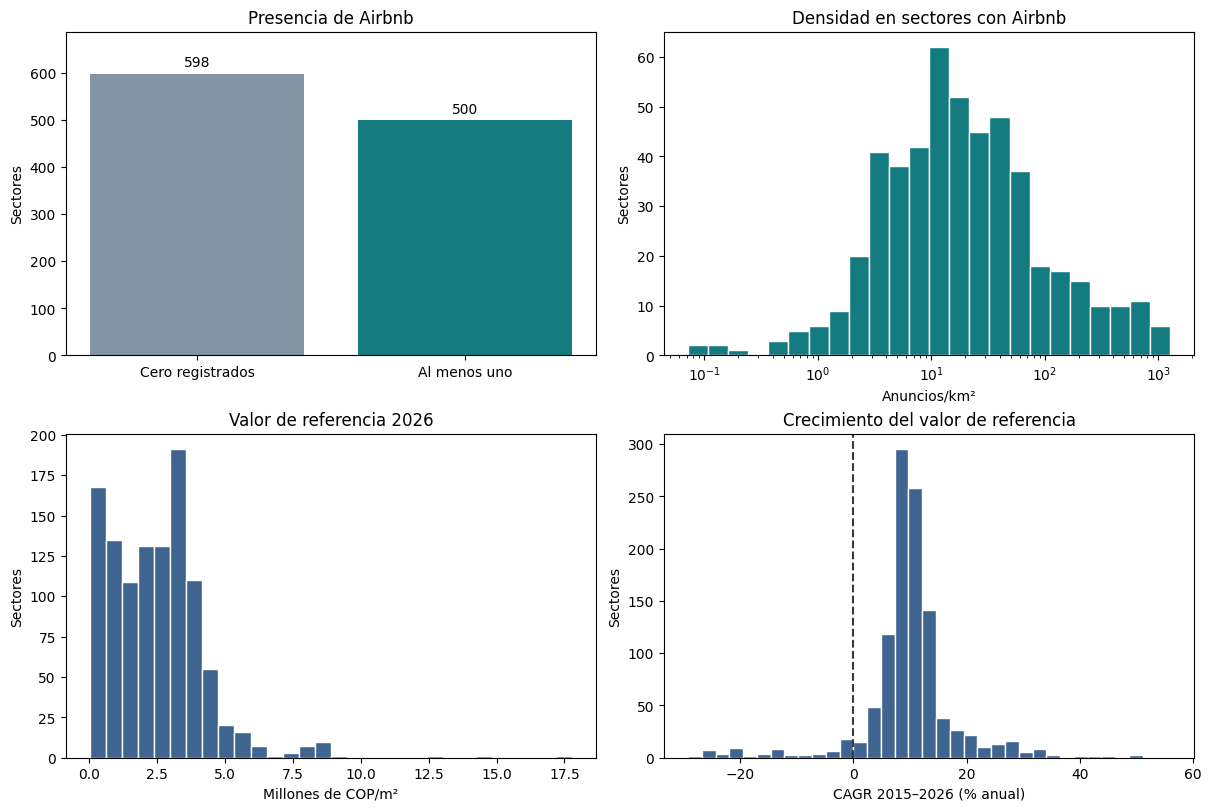

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
presencia = con_airbnb.value_counts().reindex([False, True], fill_value=0)
barras = axes[0, 0].bar(["Cero registrados", "Al menos uno"], presencia, color=["#8294a5", "#147c80"])
axes[0, 0].bar_label(barras, padding=3)
axes[0, 0].set_ylim(0, max(presencia.max(), 1) * 1.15)
axes[0, 0].set(title="Presencia de Airbnb", ylabel="Sectores")

# Los intervalos logarítmicos permiten mostrar densidades muy distintas en el mismo eje.
positivas = variables.loc[con_airbnb & variables[densidad].gt(0), densidad]
if positivas.nunique() > 1:
    intervalos = np.geomspace(positivas.min(), positivas.max(), 25)
    axes[0, 1].hist(positivas, bins=intervalos, color="#147c80", edgecolor="white")
    axes[0, 1].set_xscale("log")
else:
    axes[0, 1].hist(positivas, color="#147c80")
axes[0, 1].set(title="Densidad en sectores con Airbnb", xlabel="Anuncios/km²", ylabel="Sectores")

axes[1, 0].hist(variables[pesos] / 1_000_000, bins=30, color="#3f6490", edgecolor="white")
axes[1, 0].set(title="Valor de referencia 2026", xlabel="Millones de COP/m²", ylabel="Sectores")
axes[1, 1].hist(variables[cagr], bins=35, color="#3f6490", edgecolor="white")
axes[1, 1].axvline(0, color="#343a40", linestyle="--")
axes[1, 1].set(title="Crecimiento del valor de referencia", xlabel="CAGR 2015–2026 (% anual)", ylabel="Sectores")
plt.show()

1. Como se contrasta anteriormente la de los 1.098 sectores analizados, 500 (45,54 %) registran al menos un anuncio y 598 (54,46 %) tienen cero anuncios en la matriz.

2. Densidad de Airbnb en sectores con anuncios. Entre los 500 sectores con oferta registrada, la mediana es de 16,26 anuncios por km². La distribución presenta una cola hacia densidades altas, con un máximo de 1.277,36 anuncios por km².

3. Valor de referencia del suelo en 2026. La mediana es de 2.440.000 COP/m² y la mitad central de los sectores se ubica entre 940.000 y 3.438.000 COP/m². El máximo alcanza 17.785.000 COP/m², por encima del percentil 95 de 5.107.650 COP/m².

4. Crecimiento anual compuesto del valor de referencia, 2015–2026. El crecimiento mediano fue de 9,76 % anual y la mitad central de los sectores se ubicó entre 7,63 % y 12,32 % anual. La línea vertical en cero separa los sectores donde cayó el valor de referencia de aquellos donde aumentó. Los extremos van de −29,23 % a 56,02 % anual.

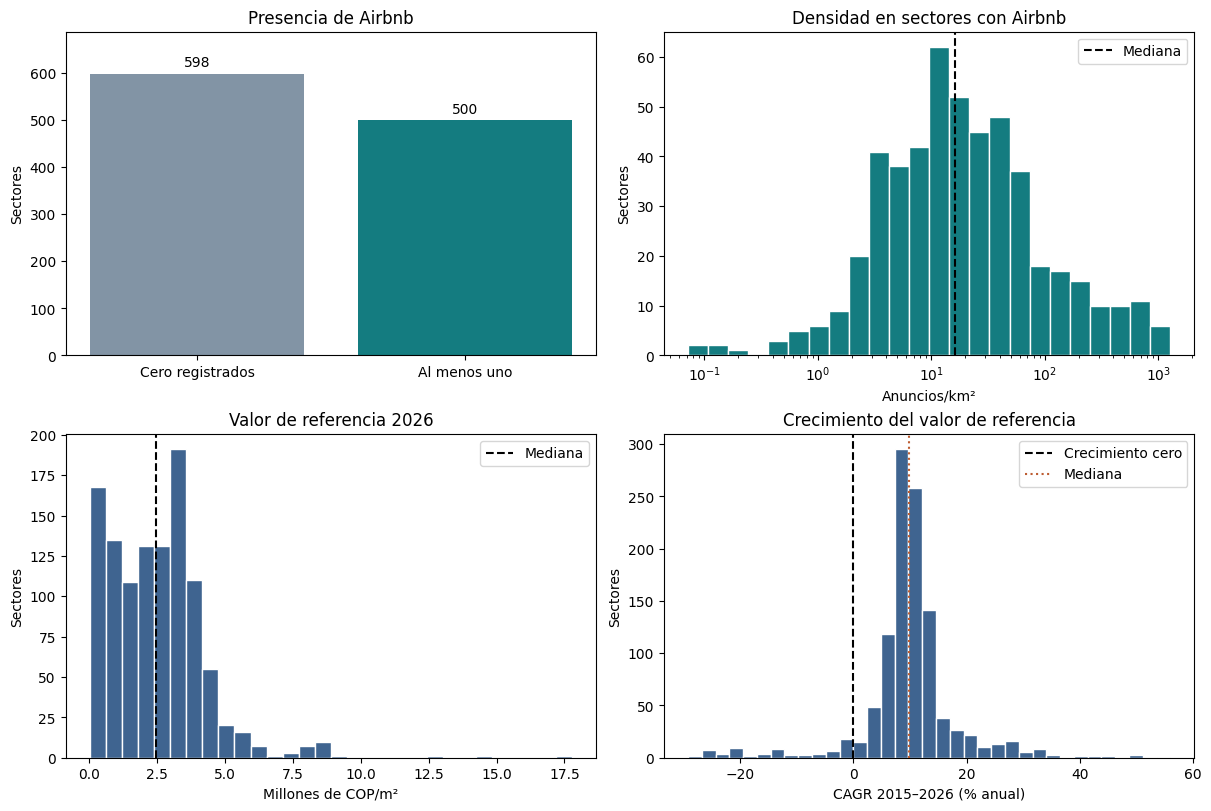

In [14]:

fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)

# 1. Presencia de Airbnb
presencia = con_airbnb.value_counts().reindex(
    [False, True], fill_value=0
)

barras = axes[0, 0].bar(
    ["Cero registrados", "Al menos uno"],
    presencia,
    color=["#8294a5", "#147c80"]
)

axes[0, 0].bar_label(barras, padding=3)
axes[0, 0].set_ylim(0, presencia.max() * 1.15)
axes[0, 0].set(title="Presencia de Airbnb", ylabel="Sectores")

# 2. Densidad Airbnb, excluyendo sectores sin anuncios
positivas = variables.loc[
    con_airbnb & variables[densidad].gt(0), densidad
]

intervalos = np.geomspace(positivas.min(), positivas.max(), 25)

axes[0, 1].hist(
    positivas, bins=intervalos,
    color="#147c80", edgecolor="white"
)

axes[0, 1].set_xscale("log")
axes[0, 1].axvline(
    positivas.median(), color="black",
    linestyle="--", label="Mediana"
)
axes[0, 1].set(
    title="Densidad en sectores con Airbnb",
    xlabel="Anuncios/km²", ylabel="Sectores"
)
axes[0, 1].legend()

# 3. Valor de referencia 2026
valores = variables[pesos] / 1_000_000

axes[1, 0].hist(
    valores, bins=30,
    color="#3f6490", edgecolor="white"
)

axes[1, 0].axvline(
    valores.median(), color="black",
    linestyle="--", label="Mediana"
)

axes[1, 0].set(
    title="Valor de referencia 2026",
    xlabel="Millones de COP/m²", ylabel="Sectores"
)
axes[1, 0].legend()

# 4. CAGR inmobiliario
crecimiento = variables[cagr]

axes[1, 1].hist(
    crecimiento, bins=35,
    color="#3f6490", edgecolor="white"
)

axes[1, 1].axvline(
    0, color="black", linestyle="--",
    label="Crecimiento cero"
)

axes[1, 1].axvline(
    crecimiento.median(), color="#bd5c31",
    linestyle=":", label="Mediana"
)

axes[1, 1].set(
    title="Crecimiento del valor de referencia",
    xlabel="CAGR 2015–2026 (% anual)",
    ylabel="Sectores"
)
axes[1, 1].legend()

plt.show()


## 6. Revisión de extremos

La densidad se contrasta con el conteo y el área. El CAGR se contrasta con el valor inicial y final. Las tablas permiten elegir casos para verificar en los insumos del ETL. El CSV final carece de banderas de imputación por sector.

In [15]:
# Seleccionar extremos para inspección, manteniendo todas las filas para el análisis.
campos_airbnb = llave + ["num_listings_airbnb", "area_km2", "densidad_airbnb_km2"]
campos_suelo = llave + ["v_ref_2015", "v_ref_2026", "cagr_15_26"]
display(matriz_final.nlargest(5, "densidad_airbnb_km2")[campos_airbnb].style.format(
    {"num_listings_airbnb": "{:.0f}", "area_km2": "{:.4f}", "densidad_airbnb_km2": "{:,.2f}"},
    decimal=",", thousands="."))
extremos = pd.concat([
    matriz_final.nsmallest(5, "cagr_15_26")[campos_suelo].assign(grupo="CAGR más bajo"),
    matriz_final.nlargest(5, "cagr_15_26")[campos_suelo].assign(grupo="CAGR más alto"),
], ignore_index=True)
display(extremos[["grupo"] + campos_suelo].style.format(
    {"v_ref_2015": formato_cop, "v_ref_2026": formato_cop, "cagr_15_26": "{:.2%}"},
    decimal=","))

,localidad,barrio,num_listings_airbnb,area_km2,densidad_airbnb_km2
1008,TEUSAQUILLO,CHAPINERO OCCIDENTAL,405,"0,3171","1.277,36"
1020,SANTA FE,VERACRUZ,438,"0,3496","1.252,71"
1063,TEUSAQUILLO,EL RECUERDO,394,"0,3353","1.175,22"
296,CHAPINERO,CHICO NORTE,883,"0,9698","910,48"
958,SANTA FE,SAMPER,188,"0,2111","890,43"


,grupo,localidad,barrio,v_ref_2015,v_ref_2026,cagr_15_26
0,CAGR más bajo,CHAPINERO,SAN ISIDRO RURAL,"$2,500,000","$55,750","-29,23%"
1,CAGR más bajo,CHAPINERO,PARAMO II,"$2,500,000","$79,900","-26,88%"
2,CAGR más bajo,SAN CRISTOBAL,TIBAQUE I,"$450,000","$16,200","-26,08%"
3,CAGR más bajo,SAN CRISTOBAL,AGUAS CLARAS,"$450,000","$16,200","-26,08%"
4,CAGR más bajo,KENNEDY,GALAN RURAL,"$1,000,000","$38,100","-25,70%"
5,CAGR más alto,USAQUEN,ESCUELA DE CABALLERIA I,"$25,000","$3,332,790","56,02%"
6,CAGR más alto,CIUDAD BOLIVAR,ESPINO,"$9,000","$790,000","50,20%"
7,CAGR más alto,CIUDAD BOLIVAR,ESPINO I,"$9,000","$790,000","50,20%"
8,CAGR más alto,SANTA FE,SANTA INES,"$220,000","$17,785,000","49,08%"
9,CAGR más alto,SAN CRISTOBAL,TIBAQUE III,"$6,000","$389,540","46,14%"


Chapinero Occidental, en Teusaquillo, encabeza la densidad con 1.277,36 anuncios/km², producto de 405 anuncios en 0,3171 km². Chicó Norte registra 883 anuncios en 0,9698 km² y queda en 910,48 anuncios/km². Los dos casos muestran por qué el área cambia el orden de los sectores según el indicador usado.

Escuela de Caballería I tiene el CAGR máximo (56,02 %), con un valor inicial de 25.000 COP/m². San Isidro Rural tiene el mínimo (−29,23 %), al pasar de $2.500.000 a 55.750 COP/m². Una base baja puede amplificar la tasa de crecimiento.

In [16]:

# Recalcular CAGR y densidad para comprobar consistencia

validos = (
    matriz_final["v_ref_2015"].gt(0) &
    matriz_final["v_ref_2026"].gt(0)
)

auditoria = matriz_final.loc[
    validos,
    llave + ["v_ref_2015", "v_ref_2026", "cagr_15_26"]
].copy()

auditoria["cagr_recalculado"] = (
    (auditoria["v_ref_2026"] / auditoria["v_ref_2015"])**(1/11) - 1
)

auditoria["diferencia_cagr"] = (
    auditoria["cagr_15_26"] - auditoria["cagr_recalculado"]
).abs()

print("Mayor diferencia absoluta en CAGR:",
      auditoria["diferencia_cagr"].max())

display(
    auditoria.nlargest(10, "diferencia_cagr")
)

# Comprobar densidad Airbnb
matriz_final["densidad_recalculada"] = (
    matriz_final["num_listings_airbnb"] /
    matriz_final["area_km2"]
)

matriz_final["diferencia_densidad"] = (
    matriz_final["densidad_airbnb_km2"] -
    matriz_final["densidad_recalculada"]
).abs()

print("Mayor diferencia absoluta en densidad:",
      matriz_final["diferencia_densidad"].max())


Mayor diferencia absoluta en CAGR: 9.71445146547012e-17


,localidad,barrio,v_ref_2015,v_ref_2026,cagr_15_26,cagr_recalculado,diferencia_cagr
3,CHAPINERO,CONCEPCION NORTE,1400000.0,4380000.0,0.109255,0.109255,9.714451e-17
106,USME,LAS GAVIOTAS,700000.0,1100000.0,0.041945,0.041945,9.714451e-17
221,ENGATIVA,PARIS,1300000.0,3300000.0,0.088376,0.088376,9.714451e-17
224,SAN CRISTOBAL,MODELO SUR,750000.0,2300000.0,0.107242,0.107242,9.714451e-17
254,ENGATIVA,LA GRANJA,1300000.0,3300000.0,0.088376,0.088376,9.714451e-17
261,CHAPINERO,PORCIUNCULA,3200000.0,8300000.0,0.090510,0.090510,9.714451e-17
297,PUENTE ARANDA,MONTES,1200000.0,3568000.0,0.104135,0.104135,9.714451e-17
307,CIUDAD BOLIVAR,CIUDAD BOLIVAR RURAL I,41564.0,146509.0,0.121349,0.121349,9.714451e-17
351,FONTIBON,EL CHANCO RURAL II,416500.0,203600.0,-0.062995,-0.062995,9.714451e-17
361,USME,DUITAMA,350000.0,843000.0,0.083192,0.083192,9.714451e-17


Mayor diferencia absoluta en densidad: 7.958078640513122e-13


## 7. Comparación por localidad

Se compara el porcentaje de sectores con Airbnb en cada localidad. Se muestran los denominadores y el conteo total de anuncios. La densidad agregada se obtiene dividiendo los anuncios de la localidad por el área de sus sectores incluidos en la matriz.

,sectores,sectores_con_airbnb,anuncios,area_incluida_km2,mediana_cagr,pct_sectores_con_airbnb,anuncios_km2_area_incluida
localidad,,,,,,,
LOS MARTIRES,8,7,45.0,1.65,0.10,87.50,27.24
BARRIOS UNIDOS,24,21,341.0,7.06,0.09,87.50,48.29
TEUSAQUILLO,30,24,2046.0,10.94,0.10,80.00,186.97
ENGATIVA,85,64,845.0,36.05,0.08,75.29,23.44
PUENTE ARANDA,56,39,230.0,22.73,0.10,69.64,10.12
USAQUEN,87,58,3338.0,67.48,0.07,66.67,49.46
SUBA,102,68,622.0,72.79,0.10,66.67,8.54
CHAPINERO,55,36,4000.0,34.76,0.07,65.45,115.07
FONTIBON,54,35,828.0,37.84,0.08,64.81,21.88


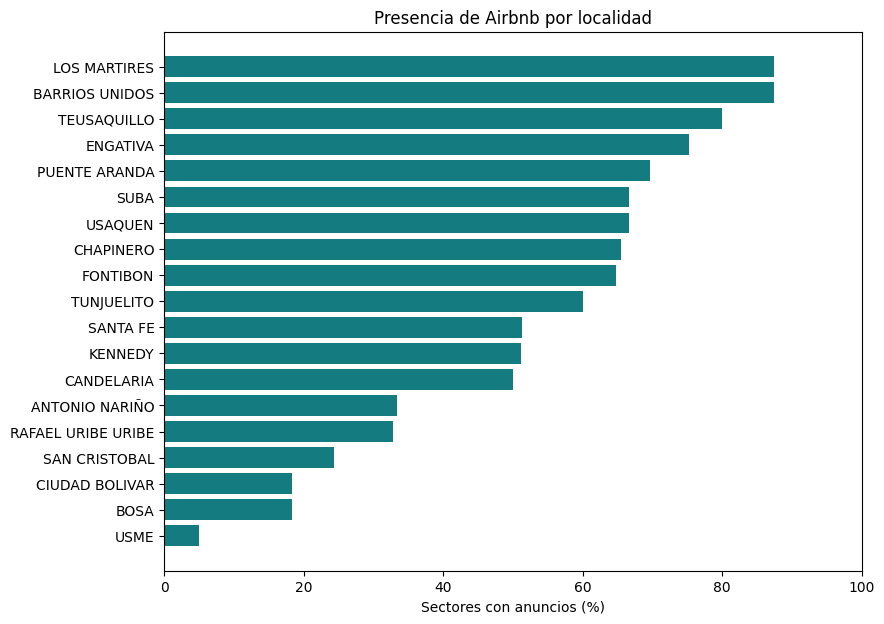

In [17]:
# Agregar conteos y áreas antes de calcular porcentajes y densidad territorial.
territorio = matriz_final.assign(con_airbnb=con_airbnb).groupby("localidad").agg(
    sectores=("barrio", "size"),
    sectores_con_airbnb=("con_airbnb", "sum"),
    anuncios=("num_listings_airbnb", "sum"),
    area_incluida_km2=("area_km2", "sum"),
    mediana_cagr=("cagr_15_26", "median"),
)
territorio["pct_sectores_con_airbnb"] = territorio.sectores_con_airbnb / territorio.sectores * 100
territorio["anuncios_km2_area_incluida"] = territorio.anuncios / territorio.area_incluida_km2
display(territorio.sort_values("pct_sectores_con_airbnb", ascending=False).round(2))

orden = territorio.sort_values("pct_sectores_con_airbnb")
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(orden.index, orden.pct_sectores_con_airbnb, color="#147c80")
ax.set(xlabel="Sectores con anuncios (%)", title="Presencia de Airbnb por localidad", xlim=(0, 100))
plt.show()

Barrios Unidos y Los Mártires tienen la mayor proporción de sectores con anuncios (87,50 % en ambos casos), con denominadores distintos (21 de 24 y 7 de 8). Chapinero registra el mayor volumen, con 4.000 anuncios en 55 sectores incluidos, de los cuales 36 tienen oferta registrada. La Candelaria muestra la mayor densidad agregada (669,46 anuncios/km²) sobre apenas dos sectores incluidos. Estos resultados distinguen extensión, volumen e intensidad y deben leerse sobre el área cubierta por la matriz.

In [18]:
territorio_presentacion = territorio.copy()

territorio_presentacion["mediana_cagr"] *= 100

display(
    territorio_presentacion
    .sort_values("pct_sectores_con_airbnb", ascending=False)
    .rename(columns={
        "mediana_cagr": "Mediana CAGR (%)",
        "pct_sectores_con_airbnb": "Sectores con Airbnb (%)",
        "anuncios_km2_area_incluida": "Anuncios/km²"
    })
    .round(2)
)

,sectores,sectores_con_airbnb,anuncios,area_incluida_km2,Mediana CAGR (%),Sectores con Airbnb (%),Anuncios/km²
localidad,,,,,,,
LOS MARTIRES,8,7,45.0,1.65,10.46,87.50,27.24
BARRIOS UNIDOS,24,21,341.0,7.06,8.71,87.50,48.29
TEUSAQUILLO,30,24,2046.0,10.94,10.15,80.00,186.97
ENGATIVA,85,64,845.0,36.05,8.06,75.29,23.44
PUENTE ARANDA,56,39,230.0,22.73,10.08,69.64,10.12
USAQUEN,87,58,3338.0,67.48,7.04,66.67,49.46
SUBA,102,68,622.0,72.79,9.69,66.67,8.54
CHAPINERO,55,36,4000.0,34.76,6.50,65.45,115.07
FONTIBON,54,35,828.0,37.84,8.19,64.81,21.88


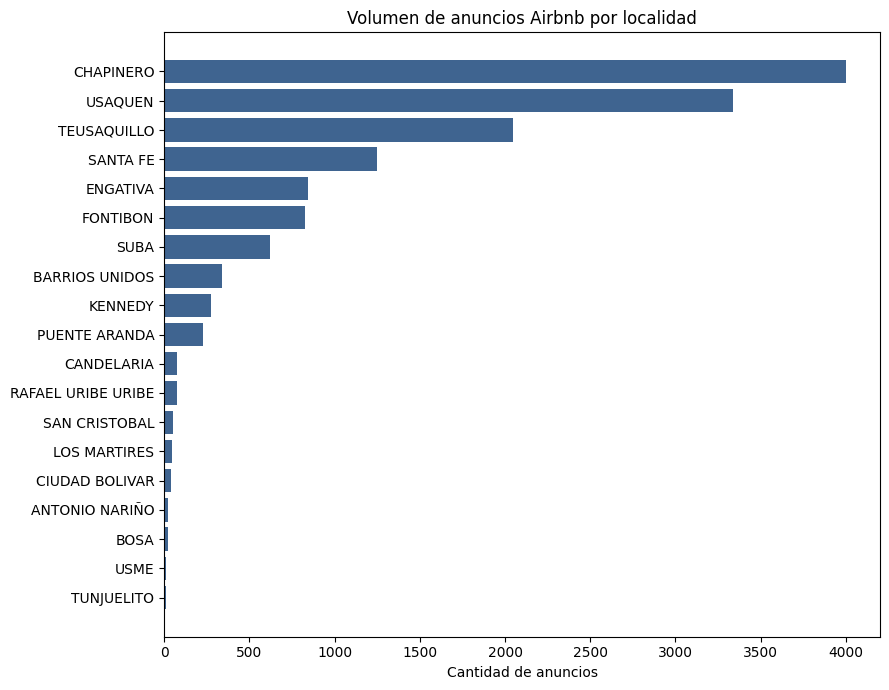

In [19]:
orden_anuncios = territorio.sort_values("anuncios")

fig, ax = plt.subplots(figsize=(9, 7))

ax.barh(
    orden_anuncios.index,
    orden_anuncios["anuncios"],
    color="#3f6490"
)

ax.set(
    xlabel="Cantidad de anuncios",
    title="Volumen de anuncios Airbnb por localidad"
)

plt.tight_layout()
plt.show()

## 8. Coincidencia de densidad alta y crecimiento alto

Se usan los percentiles 75 de toda la matriz como cortes exploratorios. Se exige densidad positiva para que un cero quede fuera del grupo de oferta alta. La dispersión y la tabla identifican sectores donde coinciden ambos indicadores. Los cortes sirven para explorar candidatos a revisión.

P75 de densidad: 14.05 anuncios/km²
P75 de CAGR: 12.32%
Sectores con ambos indicadores altos: 27 de 1098


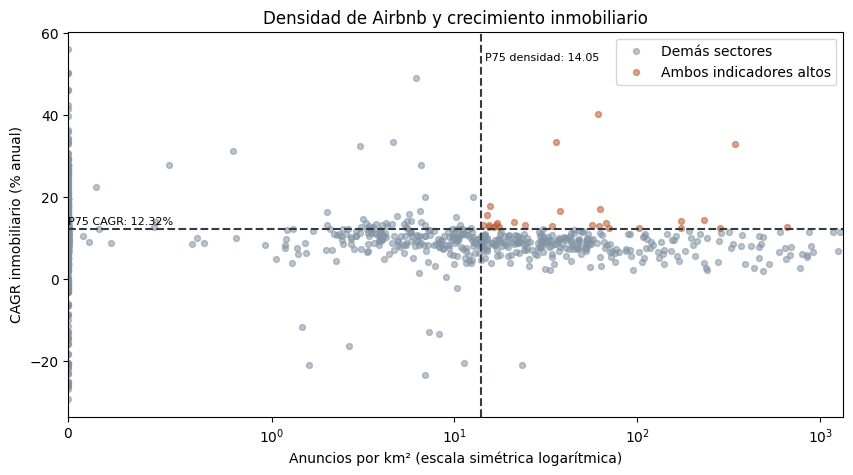

localidad
SUBA                  6
SANTA FE              5
BARRIOS UNIDOS        2
CHAPINERO             2
FONTIBON              2
KENNEDY               2
USAQUEN               2
CIUDAD BOLIVAR        1
LOS MARTIRES          1
RAFAEL URIBE URIBE    1
TEUSAQUILLO           1
TUNJUELITO            1
USME                  1
Name: Sectores con ambos indicadores altos, dtype: int64

,localidad,barrio,densidad_airbnb_km2,cagr_15_26
337,SANTA FE,LAS NIEVES,661.020169,0.127257
814,CHAPINERO,MARIA CRISTINA,344.083118,0.330117
819,TEUSAQUILLO,SANTA TERESITA,282.481184,0.124527
137,SANTA FE,LA ALAMEDA,231.450534,0.143095
539,BARRIOS UNIDOS,ALCAZARES,174.219900,0.124909
774,SANTA FE,SAGRADO CORAZON,172.750430,0.141525
196,BARRIOS UNIDOS,ALCAZARES NORTE,102.422578,0.124909
743,SANTA FE,LAS AGUAS,69.648087,0.124410
410,LOS MARTIRES,SAMPER MENDOZA,67.185548,0.136742
218,CHAPINERO,EL REFUGIO I,62.184005,0.170987


In [20]:
umbral_airbnb = matriz_final.densidad_airbnb_km2.quantile(.75)
umbral_cagr = matriz_final.cagr_15_26.quantile(.75)
prioridad = (matriz_final.densidad_airbnb_km2.gt(0)
             & matriz_final.densidad_airbnb_km2.ge(umbral_airbnb)
             & matriz_final.cagr_15_26.ge(umbral_cagr))
print(f"P75 de densidad: {umbral_airbnb:.2f} anuncios/km²")
print(f"P75 de CAGR: {umbral_cagr:.2%}")
print(f"Sectores con ambos indicadores altos: {prioridad.sum()} de {len(matriz_final)}")

# symlog conserva el cero y comprime los valores altos del eje horizontal.
fig, ax = plt.subplots(figsize=(10, 5))
for mascara, etiqueta, color in [(~prioridad, "Demás sectores", "#8294a5"),
                                  (prioridad, "Ambos indicadores altos", "#bd5c31")]:
    ax.scatter(matriz_final.loc[mascara, "densidad_airbnb_km2"],
               matriz_final.loc[mascara, "cagr_15_26"] * 100,
               alpha=.55, s=18, color=color, label=etiqueta)
ax.axvline(umbral_airbnb, color="#343a40", linestyle="--")
ax.axhline(umbral_cagr * 100, color="#343a40", linestyle="--")
ax.set_xscale("symlog", linthresh=1)
ax.set(xlabel="Anuncios por km² (escala simétrica logarítmica)",
       ylabel="CAGR inmobiliario (% anual)", title="Densidad de Airbnb y crecimiento inmobiliario")
ax.legend()

# Evitar que el eje muestre densidades negativas
ax.set_xlim(left=0)

# Identificar los umbrales
ax.text(
    umbral_airbnb * 1.05,
    matriz_final.cagr_15_26.max() * 100 * 0.95,
    f"P75 densidad: {umbral_airbnb:.2f}",
    fontsize=8
)

ax.text(
    0,
    umbral_cagr * 100 + 1,
    f"P75 CAGR: {umbral_cagr:.2%}",
    fontsize=8
)
plt.show()

seleccion = matriz_final.loc[prioridad, llave + ["densidad_airbnb_km2", "cagr_15_26"]]
display(seleccion.groupby("localidad").size().sort_values(ascending=False).rename("Sectores con ambos indicadores altos"))
display(seleccion.sort_values("densidad_airbnb_km2", ascending=False).head(15))


Con cortes de 14,05 anuncios/km² y 12,32 % anual de CAGR, 27 de 1.098 sectores (2,46 %) cumplen ambas condiciones. Suba aporta seis y Santa Fe cinco. Juntas reúnen 11 de los 27 seleccionados (40,74 %). Las Nieves tiene la mayor densidad dentro del segmento (661,02 anuncios/km² y 12,73 % de CAGR). María Cristina combina 344,08 anuncios/km² con un CAGR de 33,01 %.

La coincidencia permite acotar una primera lista de sectores para revisión. Los percentiles son cortes exploratorios relativos a esta matriz y la coincidencia por sí sola no permite atribuir el crecimiento del suelo a Airbnb.

In [21]:
resumen_prioridad = (
    matriz_final.loc[prioridad]
    .groupby("localidad")
    .agg(
        sectores=("barrio", "count"),
        mediana_densidad=("densidad_airbnb_km2", "median"),
        mediana_cagr=("cagr_15_26", "median")
    )
    .sort_values("sectores", ascending=False)
)

resumen_prioridad["mediana_cagr"] *= 100

display(resumen_prioridad.round(2))

print("Total de sectores seleccionados:", prioridad.sum())
print(
    "Participación sobre la matriz:",
    round(prioridad.mean() * 100, 2), "%"
)

,sectores,mediana_densidad,mediana_cagr
localidad,,,
SUBA,6,16.98,13.37
SANTA FE,5,172.75,13.20
BARRIOS UNIDOS,2,138.32,12.49
CHAPINERO,2,203.13,25.06
FONTIBON,2,27.71,14.63
KENNEDY,2,37.55,26.62
USAQUEN,2,26.23,23.04
CIUDAD BOLIVAR,1,34.22,12.84
LOS MARTIRES,1,67.19,13.67


Total de sectores seleccionados: 27
Participación sobre la matriz: 2.46 %


In [22]:

# Comparar sectores seleccionados frente al total de cada localidad

comparacion_prioridad = (
    matriz_final.assign(seleccionado=prioridad)
    .groupby("localidad")
    .agg(
        total_sectores=("barrio", "size"),
        sectores_seleccionados=("seleccionado", "sum")
    )
)

comparacion_prioridad["porcentaje_seleccionado"] = (
    comparacion_prioridad["sectores_seleccionados"] /
    comparacion_prioridad["total_sectores"] * 100
)

display(
    comparacion_prioridad
    .sort_values("porcentaje_seleccionado", ascending=False)
    .round(2)
)


,total_sectores,sectores_seleccionados,porcentaje_seleccionado
localidad,,,
TUNJUELITO,5,1,20.00
SANTA FE,37,5,13.51
LOS MARTIRES,8,1,12.50
BARRIOS UNIDOS,24,2,8.33
SUBA,102,6,5.88
FONTIBON,54,2,3.70
CHAPINERO,55,2,3.64
TEUSAQUILLO,30,1,3.33
KENNEDY,86,2,2.33


## 9. Mapa de los sectores seleccionados

El mapa muestra la ubicación de los sectores que superan ambos cortes. Se toma la geometría del CSV y se omiten las geometrías vacías o inválidas del mapa, con un conteo explícito.

AUDITORÍA GEOGRÁFICA
----------------------------------------
Total de sectores: 1,098
Geometrías válidas: 1,094
Geometrías omitidas: 4

AUDITORÍA DE SECTORES SELECCIONADOS
----------------------------------------
Total seleccionados: 27
Representados en el mapa: 27
Omitidos del mapa: 0

Todos los sectores seleccionados tienen geometría válida.


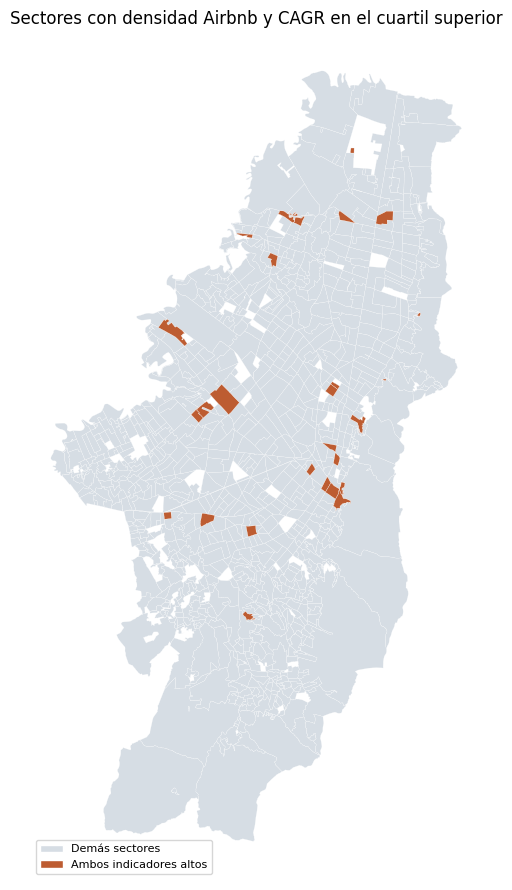

In [23]:

import geopandas as gpd
import matplotlib.pyplot as plt
from shapely import from_wkt
from matplotlib.patches import Patch

# 1. Convertir WKT a geometrías

geometrias = gpd.GeoSeries(
    from_wkt(
        matriz_final.geometry.to_numpy(),
        on_invalid="ignore"
    ),
    index=matriz_final.index
)

# Identificar geometrías válidas, no vacías y existentes
dibujables = (
    geometrias.notna()
    & geometrias.is_valid
    & ~geometrias.is_empty
)

# 2. Construir GeoDataFrame

mapa = gpd.GeoDataFrame(
    matriz_final[llave].assign(
        ambos_altos=prioridad
    ),
    geometry=geometrias
)

seleccionados_validos = prioridad & dibujables
seleccionados_omitidos = prioridad & ~dibujables

print("AUDITORÍA GEOGRÁFICA")
print("-" * 40)

print(f"Total de sectores: {len(mapa):,}")
print(f"Geometrías válidas: {dibujables.sum():,}")
print(f"Geometrías omitidas: {(~dibujables).sum():,}")

print("\nAUDITORÍA DE SECTORES SELECCIONADOS")
print("-" * 40)

print(f"Total seleccionados: {prioridad.sum():,}")
print(
    f"Representados en el mapa: "
    f"{seleccionados_validos.sum():,}"
)
print(
    f"Omitidos del mapa: "
    f"{seleccionados_omitidos.sum():,}"
)

# Mostrar sectores seleccionados sin geometría válida
if seleccionados_omitidos.any():
    print("\nSectores seleccionados sin geometría válida:")

    display(
        matriz_final.loc[
            seleccionados_omitidos,
            llave + [
                "densidad_airbnb_km2",
                "cagr_15_26"
            ]
        ]
    )
else:
    print("\nTodos los sectores seleccionados tienen geometría válida.")


if dibujables.any():

    fig, ax = plt.subplots(figsize=(8, 9))

    # Todos los sectores
    mapa.loc[dibujables].plot(
        ax=ax,
        color="#d6dde4",
        edgecolor="white",
        linewidth=0.15
    )

    # Sectores que cumplen ambos criterios
    destacados = mapa.loc[seleccionados_validos]

    if not destacados.empty:
        destacados.plot(
            ax=ax,
            color="#bd5c31",
            edgecolor="white",
            linewidth=0.2
        )

    # Leyenda
    leyenda = [
        Patch(
            facecolor="#d6dde4",
            edgecolor="white",
            label="Demás sectores"
        ),
        Patch(
            facecolor="#bd5c31",
            edgecolor="white",
            label="Ambos indicadores altos"
        )
    ]

    ax.legend(
        handles=leyenda,
        loc="lower left",
        frameon=True,
        fontsize=8
    )

    ax.set_title(
        "Sectores con densidad Airbnb y CAGR en el cuartil superior"
    )

    ax.set_axis_off()

    plt.tight_layout()
    plt.show()

else:
    print("No existen geometrías válidas para representar.")
